# BioCLIP2 × Grounding DINO: Any-box × Any-candidate evaluation

**Research question:** Does **any** of the (up to) five Grounding DINO boxes yield the correct observed species among the (up to) five BioCLIP2 candidates?

This is a **ground-truth-informed oracle / upper-bound retrieval metric**, **not** deployable end-to-end Top-1 accuracy. Ground truth chooses the winning box and species candidate. We keep exactly **one winning record per evaluated image** and a separate table for failures. We also compare ranks and inspect grounding labels.

The identification unit is `source_row` (one input photo record); `(source_row, rank)` identifies a Grounding DINO crop; `model_prediction_rank` identifies a BioCLIP candidate. Names are compared case/whitespace-insensitively, **not** synonym-resolved.


## 1. Load the actual production results

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT = Path(
    "/rs1/researchers/a/amallav/species_classification/ecological_informatics"
)
BIOCLIP_OUT = PROJECT / "notebooks/species_identification/output/bioclip2"
DETECTION_OUT = PROJECT / "notebooks/object_detection/output/analysis"
REPORT_OUT = BIOCLIP_OUT / "any_box_top5_analysis"
REPORT_OUT.mkdir(parents=True, exist_ok=True)

main = pd.read_parquet(BIOCLIP_OUT / "bioclip2_predictions_all.parquet")
top = pd.read_parquet(BIOCLIP_OUT / "bioclip2_topk_evaluated.parquet")
print("Classified crop rows:", len(main))
print("BioCLIP candidate rows:", len(top))
print("Unique image records:", main.source_row.nunique())

Classified crop rows: 29391
BioCLIP candidate rows: 146955
Unique image records: 22524


## 2. Validate keys and join metadata without inflating rows

The Top-K table contains candidate-level predictions but not all original image metadata. Use `validate="many_to_one"` to ensure one metadata row per crop.

In [ ]:
CROP_KEY = ["source_row", "rank"]
CANDIDATE_KEY = ["source_row", "rank", "model_prediction_rank"]
RANKS = ["kingdom", "phylum", "class", "order", "family", "genus", "species"]

assert not main.duplicated(CROP_KEY).any(), "Duplicate Grounding DINO crops"
assert not top.duplicated(CANDIDATE_KEY).any(), "Duplicate species candidates"
assert set(map(tuple, top[CROP_KEY].to_numpy())).issubset(
    set(map(tuple, main[CROP_KEY].to_numpy()))
), "Some candidate rows have no crop metadata"

METADATA = [
    "obs_id",
    "photo_id",
    "photo_url",
    "obs_url",
    "scientific_name",
    "common_name",
    "predator_prey_role",
    "country",
    "state",
    "city",
    "file_name",
    "image_local_path",
    "grounding_dino_prompt",
    "label",
    "score",
    "x0",
    "y0",
    "x1",
    "y1",
    "crop_x0",
    "crop_y0",
    "crop_x1",
    "crop_y1",
    "was_out_of_bounds",
    "box_area_frac",
    "n_detections",
]
METADATA = [col for col in METADATA if col in main.columns]

# Top-K already has species ground truth and rank comparisons. Only attach
# non-overlapping metadata fields to avoid suffix collisions.
attached = [c for c in METADATA if c not in top.columns]
all_candidates = top.merge(
    main[CROP_KEY + attached], on=CROP_KEY, how="left", validate="many_to_one"
)
assert len(all_candidates) == len(top), "Candidate rows increased during merge"

# Explicit column names: 'rank' is detection rank; model_prediction_rank
# is the BioCLIP candidate position. 'score' is the detector confidence.
all_candidates = all_candidates.rename(
    columns={
        "rank": "dino_rank",
        "score": "dino_score",
        "label": "dino_label",
        "model_score": "bioclip_score",
        "model_prediction_rank": "bioclip_rank",
    }
)
print("Merged candidate rows:", len(all_candidates))

Merged candidate rows: 146955


## 3. Label comparability and species-match flags

Missing reference species must **not** be counted as a model failure. Distinguish missing truth from a genuine no-match. A species match requires an exact normalized scientific-name string.

In [4]:
def normalize_name(value):
    if value is None or pd.isna(value):
        return None
    result = " ".join(str(value).split()).casefold()
    return result or None


assert {"species_name", "model_species_name"}.issubset(all_candidates.columns)
all_candidates["truth_species_normalized"] = all_candidates["species_name"].map(
    normalize_name
)
all_candidates["pred_species_normalized"] = all_candidates["model_species_name"].map(
    normalize_name
)
all_candidates["species_comparable"] = (
    all_candidates["truth_species_normalized"].notna()
    & all_candidates["pred_species_normalized"].notna()
)
all_candidates["species_exact_match"] = all_candidates[
    "species_comparable"
] & all_candidates["truth_species_normalized"].eq(
    all_candidates["pred_species_normalized"]
)

# Classifier scores are used only to break ties after choosing lower ranks.
all_candidates = all_candidates.sort_values(
    ["source_row", "dino_rank", "bioclip_rank", "bioclip_score"],
    ascending=[True, True, True, False],
    kind="stable",
)


## 4. Construct one winning row per matched image

**Winner selection (reproducible):** among matching candidates, prefer the lowest Grounding DINO rank, then the lowest BioCLIP rank; score breaks remaining ties. This policy is arbitrary but fixed and easy to audit. It selects *which match to display*, not whether an image is a match.

In [5]:
wins_all = all_candidates.loc[all_candidates["species_exact_match"]].copy()
winners = wins_all.drop_duplicates("source_row", keep="first").copy()
winners["species_matched"] = True

WIN_COLS = [
    "source_row",
    "obs_id",
    "photo_id",
    "photo_url",
    "obs_url",
    "scientific_name",
    "species_name",
    "common_name",
    "predator_prey_role",
    "country",
    "state",
    "city",
    "file_name",
    "image_local_path",
    "grounding_dino_prompt",
    "dino_rank",
    "dino_score",
    "dino_label",
    "n_detections",
    "x0",
    "y0",
    "x1",
    "y1",
    "crop_x0",
    "crop_y0",
    "crop_x1",
    "crop_y1",
    "box_area_frac",
    "was_out_of_bounds",
    "bioclip_rank",
    "bioclip_score",
    "model_species_name",
    "model_common_name",
    "deepest_shared_rank",
    "taxonomic_distance",
    "taxonomic_relationship",
    "species_matched",
] + [f"model_{r}_name" for r in RANKS]
WIN_COLS = [c for c in WIN_COLS if c in winners.columns]
winners = winners[WIN_COLS]
assert winners["source_row"].is_unique
print("Images with at least one exact species match:", len(winners))
display(winners.head())

Images with at least one exact species match: 15989


,source_row,obs_id,photo_id,photo_url,obs_url,scientific_name,species_name,common_name,predator_prey_role,country,...,taxonomic_distance,taxonomic_relationship,species_matched,model_kingdom_name,model_phylum_name,model_class_name,model_order_name,model_family_name,model_genus_name,model_species_name
0,0,338604,421440,https://inaturalist-open-data.s3.amazonaws.com...,http://conabio.inaturalist.org/observations/33...,Geococcyx californianus,Geococcyx californianus,Greater Roadrunner,predator,Mexico,...,0.0,Same species,True,Animalia,Chordata,Aves,Cuculiformes,Cuculidae,Geococcyx,Geococcyx californianus
5,1,338604,421441,https://inaturalist-open-data.s3.amazonaws.com...,http://conabio.inaturalist.org/observations/33...,Geococcyx californianus,Geococcyx californianus,Greater Roadrunner,predator,Mexico,...,0.0,Same species,True,Animalia,Chordata,Aves,Cuculiformes,Cuculidae,Geococcyx,Geococcyx californianus
10,2,338604,421442,https://inaturalist-open-data.s3.amazonaws.com...,http://conabio.inaturalist.org/observations/33...,Geococcyx californianus,Geococcyx californianus,Greater Roadrunner,predator,Mexico,...,0.0,Same species,True,Animalia,Chordata,Aves,Cuculiformes,Cuculidae,Geococcyx,Geococcyx californianus
20,3,338604,421443,https://inaturalist-open-data.s3.amazonaws.com...,http://conabio.inaturalist.org/observations/33...,Geococcyx californianus,Geococcyx californianus,Greater Roadrunner,predator,Mexico,...,0.0,Same species,True,Animalia,Chordata,Aves,Cuculiformes,Cuculidae,Geococcyx,Geococcyx californianus
50,7,420386,529902,https://inaturalist-open-data.s3.amazonaws.com...,http://www.inaturalist.org/observations/420386,Lampropeltis getula,Lampropeltis getula,Eastern Kingsnake,NaN,United States,...,5.0,"Same phylum, different class",True,Animalia,Chordata,Squamata,,Colubridae,Lampropeltis,Lampropeltis getula


## 5. Separate evaluated failures from missing labels

The failure set consists of images with an available observed species and **at least one candidate prediction**, but **no match anywhere**. Also report images with no classifier prediction and missing truth separately.

In [6]:
# A reference species is an image-level property; derive it from main
# rather than only the candidate rows.
image_base = (
    main.sort_values(["source_row", "rank"]).drop_duplicates("source_row").copy()
)
image_base["truth_species_normalized"] = image_base["species_name"].map(normalize_name)
image_base["reference_available"] = image_base["truth_species_normalized"].notna()

candidate_images = set(all_candidates["source_row"])
matched_images = set(winners["source_row"])
image_base["has_candidates"] = image_base["source_row"].isin(candidate_images)
image_base["any_species_match"] = image_base["source_row"].isin(matched_images)
image_base["outcome"] = np.select(
    [
        ~image_base["reference_available"],
        ~image_base["has_candidates"],
        image_base["any_species_match"],
    ],
    ["missing_reference_species", "no_bioclip_candidates", "matched"],
    default="no_species_match",
)

failures = image_base.loc[image_base["outcome"] == "no_species_match"].copy()
no_candidates = image_base.loc[image_base["outcome"] == "no_bioclip_candidates"].copy()
missing_truth = image_base.loc[
    image_base["outcome"] == "missing_reference_species"
].copy()

# Save one row for each failed image, not one row per crop.
print(image_base["outcome"].value_counts(dropna=False))
assert winners["source_row"].is_unique
assert failures["source_row"].is_unique

outcome
matched                      15989
no_species_match              6114
missing_reference_species      421
Name: count, dtype: int64


## 6. Correct denominators and overall Top-5 × Top-5 retrieval

This **oracle identification recall** is conditional on images represented in the completed BioCLIP outputs and with a known reference species. It does not include images that Grounding DINO never detected. The separately reported `covered / source images` can be calculated if the full Grounding DINO manifest is available.

In [7]:
eligible_images = image_base.loc[image_base["reference_available"]].copy()
n_eligible = len(eligible_images)
n_matched = int(eligible_images["any_species_match"].sum())
n_fail = n_eligible - n_matched

summary = pd.DataFrame(
    [
        {
            "classified_images_total": len(image_base),
            "images_with_reference_species": n_eligible,
            "correct_any_box_any_candidate": n_matched,
            "not_correct_any_box_any_candidate": n_fail,
            "missing_reference_species": len(missing_truth),
            "oracle_top5x5_species_recall_pct": 100 * n_matched / n_eligible
            if n_eligible
            else np.nan,
            "oracle_top5x5_error_pct": 100 * n_fail / n_eligible
            if n_eligible
            else np.nan,
        }
    ]
)
display(summary.T.rename(columns={0: "Value"}))

# Optional full-pipeline denominator, including Grounding DINO no-detections.
manifest_path = DETECTION_OUT / "grounding_dino_all_manifest.parquet"
if manifest_path.exists():
    detector_manifest = pd.read_parquet(manifest_path)
    assert detector_manifest["source_row"].is_unique
    print("All detector-input images:", len(detector_manifest))
    print(
        "Matched fraction of ALL detector-input records:",
        f"{100 * len(winners) / len(detector_manifest):.2f}%",
    )
    print(
        "Note: fraction of all records, including missing GT and pipeline failures;"
        " report alongside the conditional oracle recall."
    )
else:
    print("Detector manifest unavailable; full-input denominator not computed.")

,Value
classified_images_total,22524.000000
images_with_reference_species,22103.000000
correct_any_box_any_candidate,15989.000000
not_correct_any_box_any_candidate,6114.000000
missing_reference_species,421.000000
oracle_top5x5_species_recall_pct,72.338597
oracle_top5x5_error_pct,27.661403


All detector-input images: 23091
Matched fraction of ALL detector-input records: 69.24%
Note: fraction of all records, including missing GT and pipeline failures; report alongside the conditional oracle recall.


## 7. Taxonomic-level retrieval (any box × any candidate)

Each taxonomic rank is evaluated **independently**, with one vote per image. An image succeeds at family level if at least one evaluated candidate has the observed family. This is a *different, more permissive* question from matching all ancestral ranks on the same candidate. The table shows the number of images with a comparable pair for each rank.

In [8]:
rank_results = []
for tax_rank in RANKS:
    gt_col, pred_col = f"{tax_rank}_name", f"model_{tax_rank}_name"
    if gt_col not in all_candidates or pred_col not in all_candidates:
        continue
    gt = all_candidates[gt_col].map(normalize_name)
    pred = all_candidates[pred_col].map(normalize_name)
    comparable = gt.notna() & pred.notna()
    work = all_candidates.loc[comparable, ["source_row"]].copy()
    work["matched"] = gt.loc[comparable].eq(pred.loc[comparable]).to_numpy()
    image_correct = work.groupby("source_row")["matched"].any()
    n = len(image_correct)
    rank_results.append(
        {
            "taxonomic_rank": tax_rank,
            "evaluable_images": n,
            "correct_images_any_box_any_candidate": int(image_correct.sum()),
            "incorrect_images": int((~image_correct).sum()),
            "oracle_retrieval_accuracy_pct": 100 * image_correct.mean()
            if n
            else np.nan,
            "images_unresolved_or_without_candidate": len(image_base) - n,
        }
    )
rank_accuracy = pd.DataFrame(rank_results)
display(rank_accuracy)

,taxonomic_rank,evaluable_images,correct_images_any_box_any_candidate,incorrect_images,oracle_retrieval_accuracy_pct,images_unresolved_or_without_candidate
0,kingdom,22524,22435,89,99.604866,0
1,phylum,22524,22092,432,98.082046,0
2,class,22000,19169,2831,87.131818,524
3,order,21534,18522,3012,86.012817,990
4,family,22521,19231,3290,85.391412,3
5,genus,22485,17967,4518,79.906604,39
6,species,22103,15989,6114,72.338597,421


## 8. Understand the winning ranks

Which detector box and BioCLIP candidate actually supplied the match? These counts are based on the deterministic winner selection defined in section 4.

,dino_rank,bioclip_rank,matched_images
0,1,1,12267
1,1,2,1873
2,1,3,786
3,1,4,483
4,1,5,321
5,2,1,110
6,2,2,39
7,2,3,28
8,2,4,19
9,2,5,15


Winning Grounding DINO rank:


dino_rank
1    15730
2      211
3       40
4        7
5        1
Name: count, dtype: int64

Winning BioCLIP species candidate rank:


bioclip_rank
1    12402
2     1920
3      820
4      506
5      341
Name: count, dtype: int64

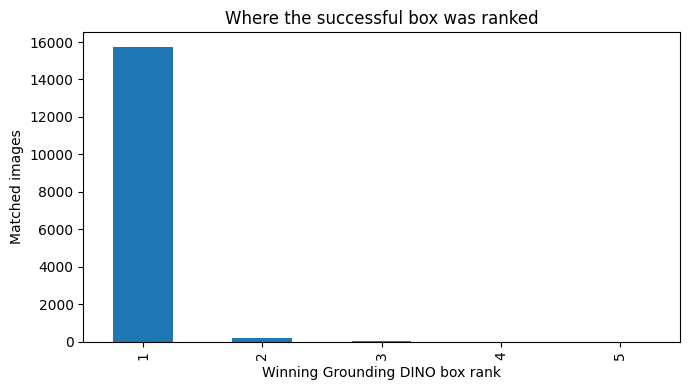

In [9]:
winner_ranks = (
    winners.groupby(["dino_rank", "bioclip_rank"])
    .size()
    .reset_index(name="matched_images")
    .sort_values(["dino_rank", "bioclip_rank"])
)
display(winner_ranks)

print("Winning Grounding DINO rank:")
display(winners["dino_rank"].value_counts().sort_index())
print("Winning BioCLIP species candidate rank:")
display(winners["bioclip_rank"].value_counts().sort_index())

plt.figure(figsize=(7, 4))
winners["dino_rank"].value_counts().sort_index().plot.bar()
plt.xlabel("Winning Grounding DINO box rank")
plt.ylabel("Matched images")
plt.title("Where the successful box was ranked")
plt.tight_layout()
plt.show()

## 9. What do detector labels tell us about failures?

Grounding DINO labels are *text-grounding phrases*, not verified classes. We can compare their frequency in failed vs matched images, but keyword-based phrases do not prove a wrong target. Use the **Rank-1 detector label** once per image for a fair comparison, and inspect representative images afterward.

In [10]:
first_crop = (
    main.sort_values(["source_row", "rank"])
    .drop_duplicates("source_row")[["source_row", "label", "score", "box_area_frac"]]
    .rename(
        columns={
            "label": "top_dino_label",
            "score": "top_dino_score",
            "box_area_frac": "top_dino_box_area_frac",
        }
    )
)
image_labels = image_base[
    ["source_row", "outcome", "scientific_name", "photo_id", "image_local_path"]
].merge(first_crop, on="source_row", how="left", validate="one_to_one")
labels_eligible = image_labels.loc[
    image_labels["outcome"].isin(["matched", "no_species_match"])
].copy()
labels_eligible["top_dino_label_norm"] = (
    labels_eligible["top_dino_label"]
    .fillna("<missing>")
    .astype(str)
    .str.strip()
    .str.casefold()
)

label_stats = (
    labels_eligible.groupby(["top_dino_label_norm", "outcome"])
    .size()
    .unstack(fill_value=0)
)
for col in ["matched", "no_species_match"]:
    if col not in label_stats:
        label_stats[col] = 0
label_stats["total_images"] = label_stats["matched"] + label_stats["no_species_match"]
label_stats["failure_rate_pct"] = (
    100 * label_stats["no_species_match"] / label_stats["total_images"]
)
label_stats = label_stats.sort_values("no_species_match", ascending=False).reset_index()

print("Most common detector labels among unsuccessful images:")
display(label_stats.head(30))
print("High-frequency labels by failure rate (minimum 20 images):")
display(
    label_stats.query("total_images >= 20")
    .sort_values("failure_rate_pct", ascending=False)
    .head(25)
)

Most common detector labels among unsuccessful images:


outcome,top_dino_label_norm,matched,no_species_match,total_images,failure_rate_pct
0,brown bird,1206,351,1557,22.543353
1,beetle,241,273,514,53.112840
2,black bird,1172,266,1438,18.497914
3,brown butterfly,372,225,597,37.688442
4,leaf gall,0,196,196,100.000000
5,brown snake,294,161,455,35.384615
6,brown spider,466,127,593,21.416526
7,brown lizard,163,117,280,41.785714
8,fish - eating bird,156,111,267,41.573034
9,blue bird,1184,105,1289,8.145849


High-frequency labels by failure rate (minimum 20 images):


outcome,top_dino_label_norm,matched,no_species_match,total_images,failure_rate_pct
4,leaf gall,0,196,196,100.000000
15,medium - sized bird,0,67,67,100.000000
16,green tree frog,3,65,68,95.588235
34,green fish,8,35,43,81.395349
52,greenish - brown frog,8,21,29,72.413793
62,crab spider,7,18,25,72.000000
36,green grasshopper,14,34,48,70.833333
19,brown insect,25,58,83,69.879518
25,brown beetle,22,50,72,69.444444
12,brown fish,44,85,129,65.891473


## 10. Best available wrong candidate for each failure

Useful for inspection: choose a *diagnostic* wrong candidate based on the smallest resolvable taxonomic distance, then lower detector and classifier ranks. This uses the observer taxonomy and therefore **must never be called a deployable box-selection method**. Unresolved distances are kept as missing.

In [11]:
failed_candidates = all_candidates.loc[
    all_candidates["source_row"].isin(failures["source_row"])
].copy()
if "taxonomic_distance" in failed_candidates.columns:
    failed_candidates["distance_numeric"] = pd.to_numeric(
        failed_candidates["taxonomic_distance"], errors="coerce"
    )
    failed_candidates = failed_candidates.sort_values(
        ["source_row", "distance_numeric", "dino_rank", "bioclip_rank"],
        na_position="last",
        kind="stable",
    )
else:
    failed_candidates = failed_candidates.sort_values(
        ["source_row", "dino_rank", "bioclip_rank"], kind="stable"
    )
closest_failure = failed_candidates.drop_duplicates("source_row").copy()
inspect_cols = [
    c
    for c in [
        "source_row",
        "photo_id",
        "scientific_name",
        "dino_label",
        "dino_rank",
        "dino_score",
        "bioclip_rank",
        "bioclip_score",
        "model_species_name",
        "deepest_shared_rank",
        "taxonomic_distance",
        "taxonomic_relationship",
        "image_local_path",
        "crop_x0",
        "crop_y0",
        "crop_x1",
        "crop_y1",
    ]
    if c in closest_failure.columns
]
display(closest_failure[inspect_cols].head(20))

,source_row,photo_id,scientific_name,dino_label,dino_rank,dino_score,bioclip_rank,bioclip_score,model_species_name,deepest_shared_rank,taxonomic_distance,taxonomic_relationship,image_local_path,crop_x0,crop_y0,crop_x1,crop_y1
35,4,521779,Lycophidion capense,brown snake,1,0.448365,1,0.136192,Atractaspis boulengeri,phylum,5.0,"Same phylum, different class",/rs1/researchers/a/amallav/species_classificat...,188,238,1021,670
45,6,521820,Mochlus sundevallii,brown lizard,1,0.448004,1,0.157282,Atractaspis boulengeri,phylum,5.0,"Same phylum, different class",/rs1/researchers/a/amallav/species_classificat...,78,238,1023,672
65,9,534567,Hemidactylus turcicus,brown lizard,1,0.566397,1,0.499457,Argiope aurantia,kingdom,6.0,"Same kingdom, different phylum",/rs1/researchers/a/amallav/species_classificat...,251,2,562,639
71,10,587403,Lutra capensis capensis,otter,1,0.831297,2,0.123366,Lutra sumatrana,genus,1.0,"Same genus, different species",/rs1/researchers/a/amallav/species_classificat...,3,208,830,821
160,22,773078,Pedinorrhina trivittata,yellow beetle,1,0.799069,1,0.273288,Pedinorrhina sellata,genus,1.0,"Same genus, different species",/rs1/researchers/a/amallav/species_classificat...,129,179,891,917
265,39,1090771,Acada biseriata,brown butterfly,1,0.880154,1,0.207676,Zariaspes mythecus,family,2.0,"Same family, different genus",/rs1/researchers/a/amallav/species_classificat...,274,214,692,505
270,40,1090770,Acada biseriata,brown butterfly,1,0.501701,1,0.474931,Acada biseriatus,genus,1.0,"Same genus, different species",/rs1/researchers/a/amallav/species_classificat...,184,34,746,609
275,41,1090827,Acada biseriata,brown butterfly,1,0.848066,1,0.200153,Acada biseriatus,genus,1.0,"Same genus, different species",/rs1/researchers/a/amallav/species_classificat...,282,159,749,628
280,42,1090799,Gonia bimaculata,moth,1,0.753703,1,0.164813,Gonia distincta,genus,1.0,"Same genus, different species",/rs1/researchers/a/amallav/species_classificat...,379,142,840,641
305,44,1131788,Philoliche rubramarginata,reddish - brown fly,1,0.795061,1,0.213330,Tabanus atratus,family,2.0,"Same family, different genus",/rs1/researchers/a/amallav/species_classificat...,70,2,720,681


## 11. Save notebook results

Save the winners, failures, rank accuracy, winning-rank table, label statistics, and diagnostic closest candidates. Failure metadata is preserved even where candidates are absent; consult `errors.csv` and detector manifests for total end-to-end coverage.

In [12]:
winners.to_parquet(REPORT_OUT / "winning_species_matches.parquet", index=False)
winners.to_csv(REPORT_OUT / "winning_species_matches.csv", index=False)
failures.to_parquet(REPORT_OUT / "no_species_match_images.parquet", index=False)
missing_truth.to_parquet(REPORT_OUT / "missing_reference_species.parquet", index=False)
no_candidates.to_parquet(REPORT_OUT / "no_bioclip_candidates.parquet", index=False)
closest_failure.to_parquet(REPORT_OUT / "closest_wrong_candidates.parquet", index=False)
summary.to_csv(REPORT_OUT / "summary.csv", index=False)
rank_accuracy.to_csv(
    REPORT_OUT / "any_box_any_candidate_rank_accuracy.csv", index=False
)
winner_ranks.to_csv(REPORT_OUT / "winning_rank_combinations.csv", index=False)
label_stats.to_csv(REPORT_OUT / "failure_label_statistics.csv", index=False)
image_labels.to_parquet(
    REPORT_OUT / "image_outcomes_with_detector_labels.parquet", index=False
)
print("Saved all reports in:", REPORT_OUT)

ValueError: Duplicate column names found: ['source_row', 'obs_id', 'photo_id', 'photo_url', 'obs_url', 'scientific_name', 'species_name', 'common_name', 'predator_prey_role', 'country', 'state', 'city', 'file_name', 'image_local_path', 'grounding_dino_prompt', 'dino_rank', 'dino_score', 'dino_label', 'n_detections', 'x0', 'y0', 'x1', 'y1', 'crop_x0', 'crop_y0', 'crop_x1', 'crop_y1', 'box_area_frac', 'was_out_of_bounds', 'bioclip_rank', 'bioclip_score', 'model_species_name', 'model_common_name', 'deepest_shared_rank', 'taxonomic_distance', 'taxonomic_relationship', 'species_matched', 'model_kingdom_name', 'model_phylum_name', 'model_class_name', 'model_order_name', 'model_family_name', 'model_genus_name', 'model_species_name']

## How to interpret the findings

- **Top-5 boxes × Top-5 candidates** answers whether a correct species was **present anywhere** among the predictions. It's a **GT-assisted retrieval ceiling**, not accuracy obtainable without selecting the correct box/candidate.
- **Winning rank distributions** show where matching candidates occur, but their selection uses ground truth.
- **Per-rank percentages** use rank-specific comparable-image denominators. Compare with strict Top-1 hierarchical accuracy from the original evaluation reports; they measure different tasks.
- **Misses** in this notebook are among images that BioCLIP2 classified. For true pipeline failure rate across original images, incorporate no-detection, crop-processing failures, and missing species labels explicitly.
- **Detector label analysis** is exploratory: phrase frequencies and failure rates are associations, not proof that Grounding DINO localized the wrong object.
- **Scientific labels** can include taxonomic synonyms or unresolved species names. Exact string comparison can undercount semantically equivalent taxonomy; document this limitation.
